# Snowflake data sources — map & exploration

Goal: understand **what lives in each Horizon Catalog database**, what your teammate used for Platts window reports, and **what you could build next** (price dashboards, swaps, market intel).

Connection pattern: `dash_irr_database/_snowflake.py` (same as the ARA report).

Companion write-up for the report itself: `TUTORIAL.md`.

## What your teammate used

From the leftover script snippet (`db_con(template='window')` + `EWMD.EWINDOW_TRADEDATA`):

| What they wrote | Actual Snowflake object |
|-----------------|-------------------------|
| `EWMD.EWINDOW_TRADEDATA` | **`SPGICI_EWINDOW_MARKETDATA.EWMD.EWINDOW_TRADEDATA`** |
| (related) | `EWINDOW_DICTIONARY`, `EWINDOW_METADATA` in the same schema |

That table alone powers the **window orders / counterparty / intraday / volume / Sankey** parts of the report.

They did **not** leave an obvious dependency on Platts assessment curves. We later found those in:

| Need | Object |
|------|--------|
| Official MOPL differential curve | **`SPGICI_MARKETDATA_SHARE.MDV2.PRICEDATA`** symbol **`AMOPM00`** |
| Symbol dictionary | `SPGICI_MARKETDATA_SHARE.MDV2.REF_DATA_MARKETDATA` |

So for window reports: **eWindow DB = teammate core**; **MarketData share = assessments/curves we added**.

In [2]:
import sys
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path("..") / "dash_irr_database"))
from _snowflake import SnowFlake

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)


def sf(database: str, schema: str = "PUBLIC") -> SnowFlake:
    return SnowFlake(database=database, schema=schema)


def run_sql(database: str, sql: str, schema: str = "PUBLIC", params=None) -> pd.DataFrame:
    conn = sf(database, schema)
    cur = conn._conn.cursor()
    cur.execute(sql, params or [])
    try:
        df = cur.fetch_pandas_all()
    except Exception:
        rows = cur.fetchall()
        cols = [c[0] for c in cur.description] if cur.description else []
        df = pd.DataFrame(rows, columns=cols)
    conn._conn.close()
    return df


def list_schemas(database: str) -> list[str]:
    df = run_sql(database, f"SHOW SCHEMAS IN DATABASE {database}")
    # SHOW SCHEMAS: name is usually column 'name'
    name_col = "name" if "name" in df.columns else df.columns[1]
    return [s for s in df[name_col].tolist() if str(s).upper() != "INFORMATION_SCHEMA"]


def list_tables(database: str, schema: str) -> pd.DataFrame:
    return run_sql(database, f"SHOW TABLES IN {database}.{schema}", schema=schema)

print("helpers ready")

c:\Users\luiscarlos.gaitan\OneDrive - Jain Global\Coding\.venv\Lib\site-packages\snowflake\connector\vendored\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.4.3)/charset_normalizer (3.4.6) doesn't match a supported version!
  warnings.warn(


helpers ready


## Catalog overview — what’s useful for oil/products work

Based on the Horizon Catalog screenshot + our probes. Focus on **commodity / trading** DBs (ignore Snowflake system / learning DBs).

| Database | Kind | What’s inside (high level) | Good for building… |
|----------|------|----------------------------|--------------------|
| **`SPGICI_EWINDOW_MARKETDATA`** | Share | Live Platts eWindow order book / trades | Window reports, quote evolution, counterparty heatmaps, liquidity dashboards |
| **`SPGICI_MARKETDATA_SHARE`** | Share | Platts assessments (`MDV2.PRICEDATA`), ref data, forward curves (`FC`) | EOD price dashboards, MOPL/cracks, symbol browsers, curve monitors |
| **`ICE`** | Local/vendor | Futures / options prices (e.g. gasoil) | Swap vs futures dashboards, ICE LSGO overlays, term structure |
| **`COMMOD` / `COMMOD_UAT`** | Local | Internal JG price views (`PRICES_EOD`, flash, RT) | Firm marks dashboard — **not** Platts assessments |
| **`TRADING` / `TRADING_UAT`** | Local | OMS / positions | P&L / position risk — not window assessments |
| **`BLOOMBERG`** | Vendor | BVAL / snaps | Alternative pricing checks |
| **`SPGICI_ENERGYPRICE_FORECAST`** | Share | Energy price forecasts | Scenario / forecast overlays |
| **`SPGICI_GLOBALOILDEMAND`**, **`SPGICI_WORLDOILSUPPLY`**, **`SPGICI_WORLDREFINERYDATA`** | Share | Fundamentals | Market-intel dashboards (demand, supply, refining) |
| **`SPGICI_ARBFLOW`**, LNG / EU gas shares | Share | Arb / gas / LNG analytics | Regional arb / gas dashboards |
| **`BBG_DLPLUS`**, **`EXT_FACTSET`**, etc. | Vendor | Other market data | Cross-check / equities-credit style feeds |

**Window-report stack (confirmed):** eWindow + MarketData share.  
**Swaps / paper price dashboard:** start with `ICE` + eWindow derivative markets + MarketData symbols.  
**Market intelligence (Yves-style stocks/OI/exports):** likely needs fundamentals DBs above — often **not** in eWindow.

## 1) List databases you can see

In [3]:
dbs = run_sql("COMMOD", "SHOW DATABASES")
name_col = "name" if "name" in dbs.columns else dbs.columns[1]
db_names = sorted(dbs[name_col].astype(str).tolist())
print(f"Visible databases: {len(db_names)}")
for d in db_names:
    print(" ", d)

Visible databases: 51
  APACMETALS_PROD_DB
  APACST_PROD_DB
  ASX
  BBG_BULK
  BBG_DLPLUS
  BLOOMBERG
  COMMOD
  COMMOD_UAT
  COMMON
  DATA_PLATFORM_CORE
  DBT_HOL_DEV
  DBT_HOL_PROD
  EEX
  EEX_UAT
  ENERGY_QUANTIFIED_PREVIEW
  EXT_FACTSET
  EXT_FACTSET_UAT
  FINANCE
  GOLDENSOURCE
  ICE
  INDEX_COMPOSITION
  KPLER
  KPLER_PREVIEW
  METEOLOGICA
  POC_DB
  SECURITY_MASTER
  SECURITY_MASTER_UAT
  SHR_GLOBAL_GOVERNMENT
  SHR_SF_PUBLIC_DATA_FREE
  SHR_WEATHER_ENVIRONMENT
  SNOWFLAKE
  SNOWFLAKE_LEARNING_DB
  SPGICI_ARBFLOW
  SPGICI_CHEMICALANALYTICS
  SPGICI_CRUDESUPPLYRISK
  SPGICI_ENERGYPRICE_FORECAST
  SPGICI_EUGAS
  SPGICI_EWINDOW_MARKETDATA
  SPGICI_GLOBALLNGANALYTICSPLUS_SHARE
  SPGICI_GLOBALLNGANALYTICS_SHARE
  SPGICI_GLOBALOILDEMAND
  SPGICI_MARKETDATA_SHARE
  SPGICI_MARKETINSIGHTS_NAGASPIPELINEFLOWS
  SPGICI_WORLDOILSUPPLY
  SPGICI_WORLDREFINERYDATA
  SPGLOBAL_XPRESS
  TRADING
  TRADING_UAT
  TRAYPORT
  TRAYPORT_DEV
  VENDOR_PLUS


## 2) Teammate core — `SPGICI_EWINDOW_MARKETDATA`

Schemas / tables, then a quick peek at trade data + dictionary.

In [4]:
EW_DB = "SPGICI_EWINDOW_MARKETDATA"
print("Schemas:", list_schemas(EW_DB))

ew_tables = list_tables(EW_DB, "EWMD")
tcol = "name" if "name" in ew_tables.columns else ew_tables.columns[1]
print("\nEWMD tables:")
display(ew_tables[[c for c in ew_tables.columns if c.lower() in {"name", "rows", "bytes", "comment"} or c == tcol]].head(20))

Schemas: ['EWMD']

EWMD tables:


,name,comment,rows,bytes


In [5]:
# Row count + date span for the main table your teammate queried
span = run_sql(
    EW_DB,
    """
    SELECT
        COUNT(*) AS n_rows,
        MIN(ORDER_DATE)::date AS min_date,
        MAX(ORDER_DATE)::date AS max_date
    FROM SPGICI_EWINDOW_MARKETDATA.EWMD.EWINDOW_TRADEDATA
    """,
    schema="EWMD",
)
display(span)

# Markets available (useful when adding new window products)
markets = run_sql(
    EW_DB,
    """
    SELECT MARKET, COUNT(*) AS n
    FROM SPGICI_EWINDOW_MARKETDATA.EWMD.EWINDOW_TRADEDATA
    WHERE ORDER_CANCELLED = 'F'
      AND ORDER_DATE >= DATEADD(day, -30, CURRENT_DATE())
    GROUP BY 1
    ORDER BY n DESC
    LIMIT 25
    """,
    schema="EWMD",
)
print("Top markets (last ~30 days):")
display(markets)

,N_ROWS,MIN_DATE,MAX_DATE
0,22526286,2007-06-14,2026-11-11


Top markets (last ~30 days):


,MARKET,N
0,ASIA FO Swap,34872
1,ASIA MidDist Swap,33687
2,Asia LNG Derivative,29038
3,EU Brent CFD,13215
4,ASIA Mogas Swap,11872
5,ASIA LNG Physical,9597
6,EU FO,9037
7,USGC Distillates,7610
8,EU BFOE,6940
9,ASIA FO (PVO),6645


In [6]:
# Dictionary: what each column means (great for onboarding)
dictionary = run_sql(
    EW_DB,
    """
    SELECT COLUMN_NAME, DEFINITION, DESCRIPTION_EXAMPLE
    FROM SPGICI_EWINDOW_MARKETDATA.EWMD.EWINDOW_DICTIONARY
    ORDER BY COLUMN_NAME
    """,
    schema="EWMD",
)
display(dictionary.head(30))

# Sample ARA 10ppm day (same filters as the report)
sample = run_sql(
    EW_DB,
    """
    SELECT MARKET, HUB, PRODUCT, STRIP, ORDER_TIME, ORDER_TYPE, ORDER_STATE,
           MARKET_MAKER_MNEMONIC, PRICE, ORDER_QUANTITY_TOTAL
    FROM SPGICI_EWINDOW_MARKETDATA.EWMD.EWINDOW_TRADEDATA
    WHERE ORDER_CANCELLED = 'F'
      AND ORDER_DATE = '2026-06-25'
      AND MARKET = 'EU MidDist Barge'
      AND HUB = 'ARA Smr'
      AND PRODUCT = 'Platts ULSD Brg 1-3kt ICE LSGO M1'
    ORDER BY ORDER_TIME
    LIMIT 15
    """,
    schema="EWMD",
)
print("Sample ARA 10ppm rows:")
display(sample)

,COLUMN_NAME,DEFINITION,DESCRIPTION_EXAMPLE
0,,Tradedata eWindow data model,
1,,Contains descriptions and examples of each of ...,
2,BUYER,A company/organization that acquires commoditi...,Cargill International Trading Pte Ltd
3,BUYER_MNEMONIC,A unique code assigned to individual buyers wi...,CARGILLSG
4,BUYER_PARENT,The ultimate controlling entity that stands as...,Cargill (Parent)
5,C1_BASIS_PERIOD,Combination Basis 1 Period 1,5
6,C1_BASIS_PERIOD_DETAILS,A strategic combination of financial instrumen...,See TQC
7,C1_PERCENTAGE,Combination Basis 1 Percentage,NULL
8,C1_PRICE,Combination Basis 1 Flat Price,8.0
9,C1_PRICE_BASIS,Combination Basis 1,MOPS 380


Sample ARA 10ppm rows:


,MARKET,HUB,PRODUCT,STRIP,ORDER_TIME,ORDER_TYPE,ORDER_STATE,MARKET_MAKER_MNEMONIC,PRICE,ORDER_QUANTITY_TOTAL
0,EU MidDist Barge,ARA Smr,Platts ULSD Brg 1-3kt ICE LSGO M1,FE,2026-06-25 15:00:33.396,Bid,active,GLENCOREUK,-1.0,3000.0
1,EU MidDist Barge,ARA Smr,Platts ULSD Brg 1-3kt ICE LSGO M1,MW,2026-06-25 15:00:38.412,Bid,active,GLENCOREUK,-1.0,3000.0
2,EU MidDist Barge,ARA Smr,Platts ULSD Brg 1-3kt ICE LSGO M1,BE,2026-06-25 15:00:47.612,Bid,active,GLENCOREUK,-1.0,3000.0
3,EU MidDist Barge,ARA Smr,Platts ULSD Brg 1-3kt ICE LSGO M1,MW,2026-06-25 15:01:03.449,Bid,active,EXTAP,-1.0,3000.0
4,EU MidDist Barge,ARA Smr,Platts ULSD Brg 1-3kt ICE LSGO M1,BE,2026-06-25 15:01:06.545,Bid,active,EXTAP,-1.0,3000.0
5,EU MidDist Barge,ARA Smr,Platts ULSD Brg 1-3kt ICE LSGO M1,FE,2026-06-25 15:01:09.113,Bid,active,EXTAP,-1.0,3000.0
6,EU MidDist Barge,ARA Smr,Platts ULSD Brg 1-3kt ICE LSGO M1,FE,2026-06-25 15:01:26.097,Offer,active,GLENCOREUK,5.0,3000.0
7,EU MidDist Barge,ARA Smr,Platts ULSD Brg 1-3kt ICE LSGO M1,MW,2026-06-25 15:01:36.158,Offer,active,GLENCOREUK,4.0,3000.0
8,EU MidDist Barge,ARA Smr,Platts ULSD Brg 1-3kt ICE LSGO M1,BE,2026-06-25 15:01:39.536,Offer,active,GLENCOREUK,4.0,3000.0
9,EU MidDist Barge,ARA Smr,Platts ULSD Brg 1-3kt ICE LSGO M1,FE,2026-06-25 15:01:42.521,Offer,withdrawn,GLENCOREUK,5.0,3000.0


### eWindow use cases you can build

- Daily **window assessment emails** (what we rebuilt)
- **Liquidity / participation** dashboards (who bids/offers most)
- Intraday **quote evolution** by strip (FE/MW/BE)
- Cycle-to-date **flow maps** (Sankey / adjacency)
- Alerting when a product’s window is unusually quiet or wide

## 3) Assessments & curves — `SPGICI_MARKETDATA_SHARE`

This is where official Platts prints live (MOPL diffs, absolute barges, cracks, etc.).

In [7]:
MD_DB = "SPGICI_MARKETDATA_SHARE"
print("Schemas:", list_schemas(MD_DB))

for schema in ["MDV2", "FC"]:
    try:
        tables = list_tables(MD_DB, schema)
        tcol = "name" if "name" in tables.columns else tables.columns[1]
        print(f"\n{schema} tables ({len(tables)}):")
        print(" ", ", ".join(tables[tcol].astype(str).tolist()[:25]))
    except Exception as e:
        print(f"{schema}: {e}")

Schemas: ['FC', 'MDV2']

MDV2 tables (0):
  

FC tables (0):
  


In [8]:
# Find ULSD / MOPL / ARA barge symbols
symbols = run_sql(
    MD_DB,
    """
    SELECT SYMBOL, DESCRIPTION, MDC
    FROM SPGICI_MARKETDATA_SHARE.MDV2.REF_DATA_MARKETDATA
    WHERE UPPER(DESCRIPTION) LIKE '%ULSD%FOB%ARA%'
       OR UPPER(DESCRIPTION) LIKE '%MOPL%'
    ORDER BY DESCRIPTION
    LIMIT 40
    """,
    schema="MDV2",
)
display(symbols)

# Official curve used in the report
mopl = run_sql(
    MD_DB,
    """
    SELECT ASSESSDATE::date AS ASSESSDATE, VALUE, BATE, UOM
    FROM SPGICI_MARKETDATA_SHARE.MDV2.PRICEDATA
    WHERE SYMBOL = 'AMOPM00'
      AND BATE = 'c'
      AND ASSESSDATE >= '2026-06-01'
      AND ASSESSDATE < '2026-06-26'
    ORDER BY ASSESSDATE
    """,
    schema="MDV2",
)
print("AMOPM00 (ULSD FOB ARA Brg v MOPL) sample:")
display(mopl.tail(10))

,SYMBOL,DESCRIPTION,MDC
0,PFNED00,FOB Mediterranean Bitumen MOPL Diff $/mt Weekly,"PU,RFP,RPR"
1,PFNEC00,FOB Northwest Europe Bitumen MOPL Diff $/mt We...,"PU,RFP,RPR"
2,AMOPI00,Gasoil .1%S (1000ppm) CIF Med Cargo MOPL Diffe...,"EB,RFP,RPR"
3,AMOPG00,Gasoil .1%S (1000ppm) FOB ARA Barge MOPL Diffe...,"EB,RFP,RPR"
4,AMOPJ00,Jet CIF NWE Cargo MOPL Differential,"EB,RFP,RPR"
5,AMOPK00,Jet FOB FARAG Barge MOPL Differential,"EB,RFP,RPR"
6,AAXXH00,Jet FOB Rdam vs ULSD 10ppm FOB ARA Barge Finan...,DR
7,AAXXM01,Jet FOB Rdam vs ULSD 10ppm FOB ARA Barge Finan...,DR
8,AAXXM02,Jet FOB Rdam vs ULSD 10ppm FOB ARA Barge Finan...,DR
9,AMOPH00,Platts Gasoil 0.1%S CIF NWE Cargo MOPL Differe...,"EB,RFP,RPR"


AMOPM00 (ULSD FOB ARA Brg v MOPL) sample:


,ASSESSDATE,VALUE,BATE,UOM
9,2026-06-12,-0.81,c,MT
10,2026-06-15,-1.82,c,MT
11,2026-06-16,-2.01,c,MT
12,2026-06-17,-2.13,c,MT
13,2026-06-18,-1.04,c,MT
14,2026-06-19,-0.23,c,MT
15,2026-06-22,0.45,c,MT
16,2026-06-23,0.34,c,MT
17,2026-06-24,2.09,c,MT
18,2026-06-25,6.18,c,MT


### MarketData share use cases

- **Price dashboard**: pick symbols from `REF_DATA_MARKETDATA`, chart `PRICEDATA`
- **Swaps / cracks / diffs**: search descriptions for `Financial`, `Crack`, `vs LS Gasoil`, `MOPL`
- **Forward curves**: explore `FC` schema views (`FORWARDCURVES_*`)
- **Cross-product monitor**: ARA barge vs Med cargo vs Singapore in one panel

In [29]:
# Find ULSD / MOPL / ARA barge symbols
symbols = run_sql(
    MD_DB,
    """
    SELECT SYMBOL, DESCRIPTION, MDC, COMMODITY, ASSESSMENT_FREQUENCY 
    FROM SPGICI_MARKETDATA_SHARE.MDV2.REF_DATA_MARKETDATA
    WHERE UPPER(DESCRIPTION) LIKE '%%'
       OR UPPER(SYMBOL) LIKE '%PCAKB03%'
       OR COMMODITY LIKE '%%'
    ORDER BY DESCRIPTION
    LIMIT 100
    """,
    schema="MDV2",
)
display(symbols)



,SYMBOL,DESCRIPTION,MDC,COMMODITY,ASSESSMENT_FREQUENCY
0,ABUSA03,#1 Busheling Delivered US South MAvg,"FME,MET,RMP,RMS,SPM,SSD,ST",Ferrous scrap,Monthly
1,ABUSA04,#1 Busheling Delivered US South WAvg,"FME,MET,RMP,RMS,SPM,SSD,ST",Ferrous scrap,Weekly
2,ABUSA00,"#1 Busheling Delivered US South,1号边角废钢运抵美国南部价,...","FME,MET,RMP,RMS,SPM,SSD,ST",Ferrous scrap,Daily (weekday)
3,ABUMA00,#1 Busheling Scrap Mexico,"FME,MET,SPM,SSD,ST",Ferrous scrap,Daily (weekday)
4,ABUMC00,#1 Busheling Scrap Mexico $/mt,"FME,MET,SPM,SSD,ST",Ferrous scrap,Daily (weekday)
...,...,...,...,...,...
95,GPBFF03,85CL Beef FCA WC US $/mt MAvg,"AGF,AGS,GPN",Beef,Monthly
96,GPBFU00,90CL Beef CIF EC US $/lb,"AGF,AGS,GPN",Beef,Daily (weekday)
97,GPBFU03,90CL Beef CIF EC US $/lb MAvg,"AGF,AGS,GPN",Beef,Monthly
98,ATALB00,90CL Beef CIF EC US $/mt,"AGF,AGS,GPN",Beef,Daily (weekday)


In [ ]:
symbols[symbols['SYMBOL']=='PCAKB03'] #.to_csv('symbols.csv')

,SYMBOL,DESCRIPTION,MDC,COMMODITY,ASSESSMENT_FREQUENCY


In [42]:
# Official curve used in the report
mopl = run_sql(
    MD_DB,
    """
    SELECT ASSESSDATE::date AS ASSESSDATE, VALUE, BATE, UOM, SYMBOL
    FROM SPGICI_MARKETDATA_SHARE.MDV2.PRICEDATA
    WHERE SYMBOL IN ('AAROA00','PCAQD00', 'AARWD00')
      AND BATE = 'c'
      AND ASSESSDATE >= '2026-01-01'
      AND ASSESSDATE < '2026-11-10'
    ORDER BY ASSESSDATE
    """,
    schema="MDV2",
)
print("Ticker sample:")

display(mopl.tail(10))

Ticker sample:


,ASSESSDATE,VALUE,BATE,UOM,SYMBOL
513,2026-11-04,118.29,c,BBL,AAROA00
514,2026-11-04,103.37,c,BBL,AARWD00
515,2026-11-04,112.03,c,BBL,PCAQD00
516,2026-11-05,108.54,c,BBL,PCAQD00
517,2026-11-05,114.57,c,BBL,AAROA00
518,2026-11-05,106.62,c,BBL,AARWD00
519,2026-11-06,120.57,c,BBL,AAROA00
520,2026-11-06,111.70,c,BBL,PCAQD00
521,2026-11-06,107.50,c,BBL,AARWD00
522,2026-11-09,104.78,c,BBL,AARWD00


<Axes: xlabel='ASSESSDATE'>

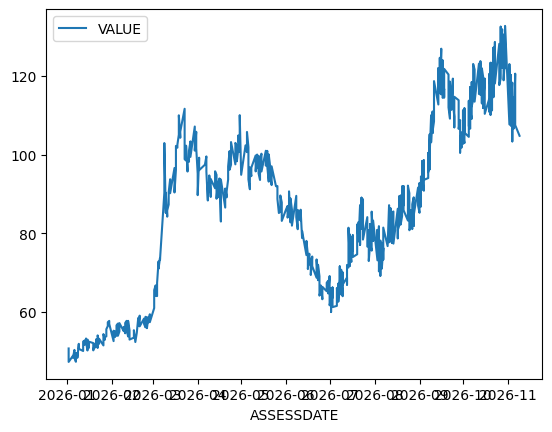

In [44]:
mopl.set_index('ASSESSDATE').plot()

## 4) Paper / futures — `ICE` (and related)

Useful when you want **swap vs futures** or ICE LSGO context next to eWindow barge diffs.

In [ ]:
ICE_DB = "ICE"
try:
    print("ICE schemas:", list_schemas(ICE_DB))
    ice_public = list_tables(ICE_DB, "PUBLIC")
    tcol = "name" if "name" in ice_public.columns else ice_public.columns[1]
    print("PUBLIC tables (sample):", ice_public[tcol].astype(str).tolist()[:30])
except Exception as e:
    print("ICE probe failed:", e)

# Broader search for price-like objects (may take a bit)
try:
    ice_hits = run_sql(
        ICE_DB,
        """
        SELECT table_schema, table_name
        FROM ICE.information_schema.tables
        WHERE UPPER(table_name) LIKE '%PRICE%'
           OR UPPER(table_name) LIKE '%FUTURE%'
           OR UPPER(table_name) LIKE '%SETT%'
        ORDER BY 1, 2
        LIMIT 40
        """,
    )
    display(ice_hits)
except Exception as e:
    print("ICE table search failed:", e)

ICE schemas: ['BASIS_SETTLEMENT_PREVIEW', 'CME', 'CTF', 'INTEGRATION', 'MFT', 'STAGE']
ICE probe failed: 002043 (02000): SQL compilation error:
Object does not exist, or operation cannot be performed.


,TABLE_SCHEMA,TABLE_NAME
0,BASIS_SETTLEMENT_PREVIEW,SETTLE_PRICE
1,CME,PRICES_RAW_FUT
2,CME,PRICES_RAW_OPT
3,CTF,PRICES_RAW
4,INTEGRATION,INT_FLASH_FUTURES
5,INTEGRATION,INT_ICE_BASIS_SETTLEMENT_PREVIEW_SETTLE_PRICE
6,INTEGRATION,INT_ICE_MFT_FUTURES
7,INTEGRATION,INT_ICE_MFT_UTILMKT_FUTURES
8,MFT,FLASH_FUTURES
9,MFT,FUTURES


## 5) Internal marks — `COMMOD`

`PRICES_EOD` / flash / RT are **JG internal** pricing views, not Platts window assessments. Still useful for a marks dashboard.

In [ ]:
commod_views = run_sql(
    "COMMOD",
    """
    SELECT table_schema, table_name, table_type
    FROM COMMOD.information_schema.tables
    WHERE UPPER(table_name) LIKE '%PRICE%'
    ORDER BY 1, 2
    LIMIT 30
    """,
)
display(commod_views)

try:
    eod_cols = run_sql("COMMOD", "DESCRIBE VIEW COMMOD.PUBLIC.PRICES_EOD")
    display(eod_cols.head(20))
except Exception as e:
    print("PRICES_EOD describe failed:", e)

,TABLE_SCHEMA,TABLE_NAME,TABLE_TYPE
0,PUBLIC,PRICES_EOD,VIEW
1,PUBLIC,PRICES_FLASH,VIEW
2,PUBLIC,PRICES_RT,VIEW
3,PUBLIC,PRICES_RT_ALT,VIEW


,name,type,kind,null?,default,primary key,unique key,check,expression,comment,policy name,privacy domain,write default
0,AS_OF_DATE,DATE,COLUMN,Y,None,N,N,None,None,None,None,None,None
1,SOURCE,VARCHAR(24),COLUMN,Y,None,N,N,None,None,None,None,None,None
2,EXCHANGE_SHORT,VARCHAR(3),COLUMN,Y,None,N,N,None,None,None,None,None,None
3,SEC_TYP,VARCHAR(6),COLUMN,Y,None,N,N,None,None,None,None,None,None
4,CONTRACT_ROOT,VARCHAR(16777216),COLUMN,Y,None,N,N,None,None,None,None,None,None
5,DESCRIPTION,VARCHAR(16777216),COLUMN,Y,None,N,N,None,None,None,None,None,None
6,MIC,VARCHAR(16777216),COLUMN,Y,None,N,N,None,None,None,None,None,None
7,STRIKE,FLOAT,COLUMN,Y,None,N,N,None,None,None,None,None,None
8,PUT_CALL,VARCHAR(16777216),COLUMN,Y,None,N,N,None,None,None,None,None,None
9,CONTRACT,VARCHAR(16777216),COLUMN,Y,None,N,N,None,None,None,None,None,None


## 6) Quick probes — `TRADING`, `BLOOMBERG`, fundamentals shares

Run these when you want to see whether a DB is worth a deeper project.

In [ ]:
PROBE_DBS = [
    "TRADING",
    "BLOOMBERG",
    "SPGICI_ENERGYPRICE_FORECAST",
    "SPGICI_GLOBALOILDEMAND",
    "SPGICI_WORLDOILSUPPLY",
    "SPGICI_WORLDREFINERYDATA",
]

for db in PROBE_DBS:
    print("\n===", db, "===")
    try:
        schemas = list_schemas(db)
        print("schemas:", schemas[:15], ("..." if len(schemas) > 15 else ""))
        # show a few tables in the first non-info schema
        for sch in schemas[:3]:
            try:
                tabs = list_tables(db, sch)
                tcol = "name" if "name" in tabs.columns else tabs.columns[1]
                names = tabs[tcol].astype(str).tolist()[:8]
                print(f"  {sch}: {names}")
            except Exception as e:
                print(f"  {sch}: {e}")
    except Exception as e:
        print("  failed:", e)


=== TRADING ===
schemas: ['TRD_DATA', 'TRD_OMS', 'TRD_POSITIONS'] 
  TRD_DATA: ['INSTRUMENT']
  TRD_OMS: []
  TRD_POSITIONS: []

=== BLOOMBERG ===
schemas: ['BBGH_FUTURES', 'BBGH_ONDEMAND'] 
  BBGH_FUTURES: ['FUTURE_GENERIC_REF', 'FUTURE_MONTH_CODE', 'FUTURE_PX', 'FUTURE_PX_DL_ADHOC_BACKFILL', 'FUTURE_REF', 'FUTURE_REF_DL', 'FUTURE_SERIES', 'FUT_CUR_GEN_TICKER']
  BBGH_ONDEMAND: ['BBG_MACRO_EVENT_DATES', 'BVAL_SNAP_PRICES', 'BVAL_SNAP_PRICES_TEST']

=== SPGICI_ENERGYPRICE_FORECAST ===
schemas: ['ENERGYPRICEFORECAST'] 
  ENERGYPRICEFORECAST: []

=== SPGICI_GLOBALOILDEMAND ===
schemas: ['MGODF'] 
  MGODF: []

=== SPGICI_WORLDOILSUPPLY ===
schemas: ['SUPPLY'] 
  SUPPLY: []

=== SPGICI_WORLDREFINERYDATA ===
schemas: ['WRD'] 
  WRD: []


## 7) Recipe: find a swap / differential symbol, then pull history

Pattern for a **prices / swaps dashboard**:

1. Search `REF_DATA_MARKETDATA` by description keywords  
2. Confirm history in `PRICEDATA`  
3. Chart in Plotly / Dash

In [ ]:
KEYWORD = "%GASOIL%SWAP%"  # try also: %CRACK%, %LSGO%, %MOPL%, %FINANCIAL%

hits = run_sql(
    MD_DB,
    f"""
    SELECT SYMBOL, DESCRIPTION, MDC
    FROM SPGICI_MARKETDATA_SHARE.MDV2.REF_DATA_MARKETDATA
    WHERE UPPER(DESCRIPTION) LIKE '{KEYWORD}'
    ORDER BY DESCRIPTION
    LIMIT 25
    """,
    schema="MDV2",
)
display(hits)

if not hits.empty:
    sym = hits.iloc[0]["SYMBOL"]
    hist = run_sql(
        MD_DB,
        """
        SELECT ASSESSDATE::date AS ASSESSDATE, VALUE, BATE, UOM, CURRENCY
        FROM SPGICI_MARKETDATA_SHARE.MDV2.PRICEDATA
        WHERE SYMBOL = %s
          AND BATE = 'c'
          AND ASSESSDATE >= DATEADD(month, -6, CURRENT_DATE())
        ORDER BY ASSESSDATE
        """,
        schema="MDV2",
        params=[sym],
    )
    print(f"History for {sym}: {len(hist)} rows")
    display(hist.tail(10))

,SYMBOL,DESCRIPTION,MDC
0,BSGSL00,Balance Month FOB Singapore 10ppm gasoil swaps...,DR
1,GRBHP01,FtS Houston Gasoil 0.1%S ARA FOB Brg Brent Crk...,RHD
2,GRBHP02,FtS Houston Gasoil 0.1%S ARA FOB Brg Brent Crk...,RHD
3,GRBHP03,FtS Houston Gasoil 0.1%S ARA FOB Brg Brent Crk...,RHD
4,GRBHP04,FtS Houston Gasoil 0.1%S ARA FOB Brg Brent Crk...,RHD
5,GRBHP05,FtS Houston Gasoil 0.1%S ARA FOB Brg Brent Crk...,RHD
6,GRBHP06,FtS Houston Gasoil 0.1%S ARA FOB Brg Brent Crk...,RHD
7,GRBHP07,FtS Houston Gasoil 0.1%S ARA FOB Brg Brent Crk...,RHD
8,GRBHP08,FtS Houston Gasoil 0.1%S ARA FOB Brg Brent Crk...,RHD
9,GRBHP09,FtS Houston Gasoil 0.1%S ARA FOB Brg Brent Crk...,RHD


History for BSGSL00: 0 rows


,ASSESSDATE,VALUE,BATE,UOM,CURRENCY


## 8) What to build next (practical shortlist)

| Idea | Primary DB(s) | Notes |
|------|---------------|-------|
| More window products (ARA 3.5%, ULSD CIF, Asia GO…) | `SPGICI_EWINDOW_MARKETDATA` | New `WindowReportConfig` rows; same pipeline |
| Assessment price board (MOPL, cracks, barges) | `SPGICI_MARKETDATA_SHARE` | Symbol picker + `PRICEDATA` |
| Swaps vs ICE futures panel | MarketData + `ICE` | Align symbols carefully |
| Counterparty / liquidity monitor | eWindow | Reuse aggregate logic from the report |
| Internal marks vs Platts | `COMMOD` + MarketData | Divergence alerts |
| Fundamentals / Yves-style intel | Global oil demand/supply/refinery shares | Often separate from window data |
| Positions / risk | `TRADING` | Different domain than assessments |

### Suggested learning path

1. Run this notebook top-to-bottom once.  
2. Change the `KEYWORD` cell and chase 2–3 symbols you care about.  
3. Read `TUTORIAL.md` for how the ARA report wires eWindow + `AMOPM00`.  
4. When ready, add a second product config and reuse the report pipeline.